# **Environment description**

I selected FrozenLake with the 8x8 map.

The environment's objective to to mobe from the starting tile to the goal time while avoiding holes, where the frozen tiles are safe to walk on. Reaching the goal rewards 1 and all other transitions reward 0. Going into a hole ends the run with no reward.

There are 64 possible states in the 8x8 grid. The observation space is Discrete(64).

There are 4 possible actions: left, right, up, and down.

If the frozen lake is slippery, the direction that it transitions one space in is random. If the lake is not slippery, it transitions to the next space in the intended direction.

The reward structure is earning 1 point by reaching the goal, otherwise earning 0 points.

The session will be terminated when the goal is reached or when the agent moves onto a hole space.

**Settings**

- Environment: FrozenLake-v1
- Map size: 8x8
- Number of states: 64
- Number of actions:4
- Slippery transitions: disabled
- State representation: discrete integer
- Q-table dimensions: 64x4


Episode: 5000, Success rate (last 5k): 0.049, Epsilon: 0.607
Episode: 10000, Success rate (last 5k): 0.246, Epsilon: 0.368
Episode: 15000, Success rate (last 5k): 0.489, Epsilon: 0.223
Episode: 20000, Success rate (last 5k): 0.683, Epsilon: 0.135
Episode: 25000, Success rate (last 5k): 0.802, Epsilon: 0.082
Episode: 30000, Success rate (last 5k): 0.882, Epsilon: 0.050
Episode: 35000, Success rate (last 5k): 0.931, Epsilon: 0.030
Episode: 40000, Success rate (last 5k): 0.959, Epsilon: 0.018
Episode: 45000, Success rate (last 5k): 0.970, Epsilon: 0.011
Episode: 50000, Success rate (last 5k): 0.980, Epsilon: 0.010


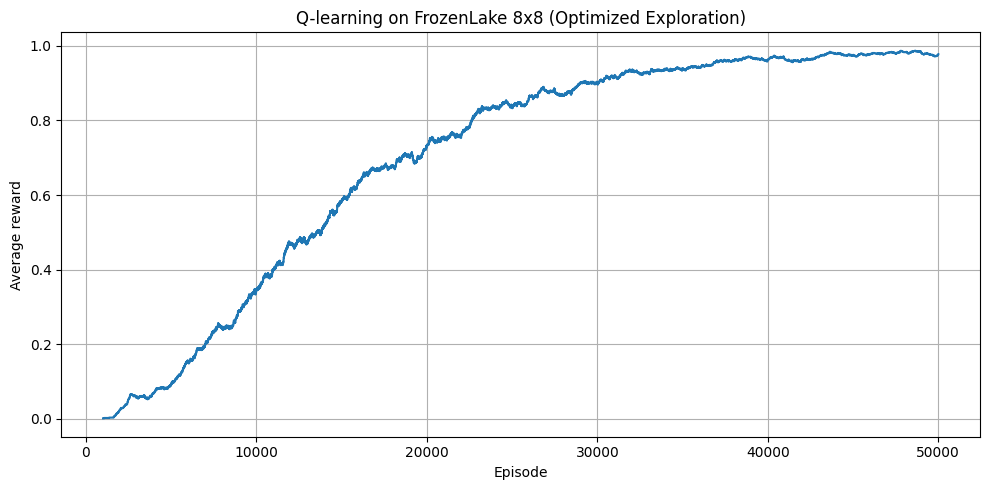


Learned Q-table (non-zero entries indicate path found):
States with learned values: 50 / 64


In [19]:
# this has been left on "best" settings
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# environment
env = gym.make(
    "FrozenLake-v1",
    map_name="8x8",
    is_slippery=False
)

# hyperparameters optimized for sparse reward exploration
alpha = 0.5            # learning rate
gamma = 0.50           # discount factor
epsilon = 1.0          # initial exploration probability
epsilon_min = 0.01     # minimum exploration probability
epsilon_decay = 0.9999 # slower decay to ensure enough early-stage exploration

episodes = 50000
max_steps = 100

# reproducibility
np.random.seed(42)

# initialize the Q-table
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

# store episode rewards and successes
episode_rewards = []
episode_successes = []

# training loop
for episode in range(episodes):

    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):

        # epsilon-greedy action selection
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            # Add a small random choice among best actions to break ties randomly when Q is all zeros
            best_actions = np.flatnonzero(Q[state] == np.max(Q[state]))
            action = np.random.choice(best_actions)

        # take action
        next_state, reward, terminated, truncated, info = env.step(action)

        # Q-learning update
        target = reward
        if not terminated:
            target += gamma * np.max(Q[next_state])

        Q[state, action] += alpha * (target - Q[state, action])

        # move to next state
        state = next_state
        total_reward += reward

        # stop if episode ends
        if terminated or truncated:
            break

    # decay exploration after each episode
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    episode_rewards.append(total_reward)
    episode_successes.append(int(total_reward > 0))

    # display progress
    if (episode + 1) % 5000 == 0:
        recent_success = np.mean(episode_successes[-5000:])
        print(
            f"Episode: {episode + 1}, "
            f"Success rate (last 5k): {recent_success:.3f}, "
            f"Epsilon: {epsilon:.3f}"
        )

env.close()

# plot training rewards
window = 1000
average_rewards = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))
plt.plot(
    np.arange(window, len(episode_rewards) + 1),
    average_rewards
)
plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("Q-learning on FrozenLake 8x8 (Optimized Exploration)")
plt.grid(True)
plt.tight_layout()
plt.show()

# display learned Q-table
print("\nLearned Q-table (non-zero entries indicate path found):")
non_zero_rows = np.any(Q > 0, axis=1)
print(f"States with learned values: {np.sum(non_zero_rows)} / {n_states}")

# save Q-table for later evaluation
np.save("frozenlake_qtable.npy", Q)

# **Baseline Training:**
- Learning rate: 0.1
- Discount factor: 0.99
- Initial exploration rate: 1.0
- Minimum exploration rate: 0.01
- Exploration decay rate: -.9999
- Number of training episodes: 50000
- Maximum steps per episode: 100
- Slippery transitions: disabled
- Schedule: exponantial decay

The graph shows clear improvement in performance over training, success rate from 0.106 to 0.985

Output:

Episode: 5000, Success rate (last 5k): 0.106, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.386, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.622, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.788, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.873, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.923, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.950, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.968, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.982, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.985, Epsilon: 0.010

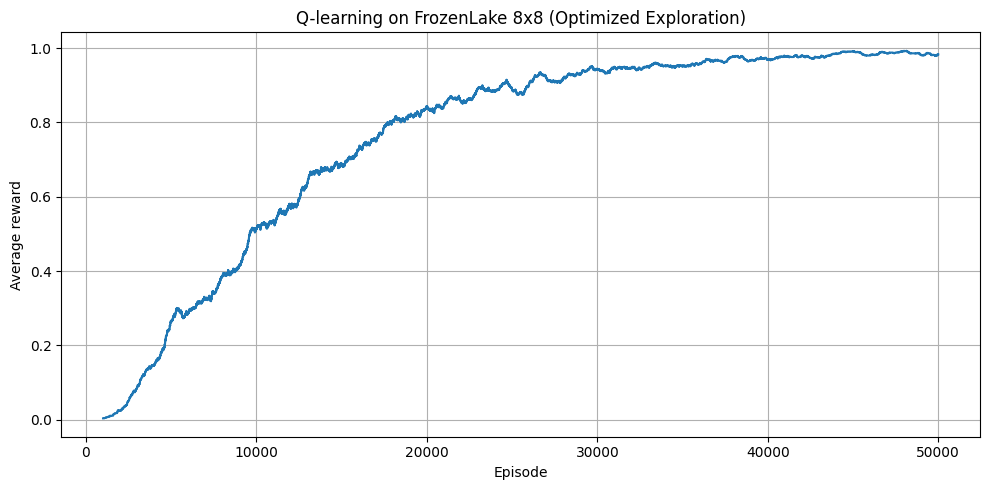

Learned Q-table (non-zero entries indicate path found):

States with learned values: 50 / 64


# **Learning-rate experiment:**

The 0.2 learning rate performed better in early learning, with 0.5 and 0.9 catching up shortly after. The 0.5 learning rate finished with the highest success rate by a small margin. Overall, 0.5 is the best because it had the highest success rate in the end, but they all performed similarly.

**Learning rate = 0.2**

Episode: 5000, Success rate (last 5k): 0.077, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.256, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.490, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.673, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.813, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.880, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.926, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.954, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.970, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.981, Epsilon: 0.010

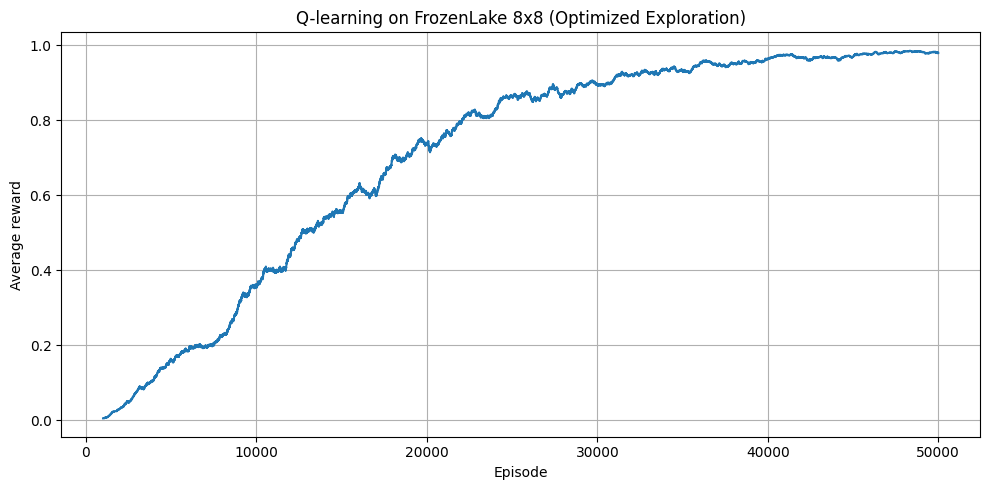

Learned Q-table (non-zero entries indicate path found):

States with learned values: 50 / 64


**Learning rate = 0.5**


Episode: 5000, Success rate (last 5k): 0.054, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.245, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.486, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.679, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.812, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.879, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.923, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.959, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.972, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.984, Epsilon: 0.010

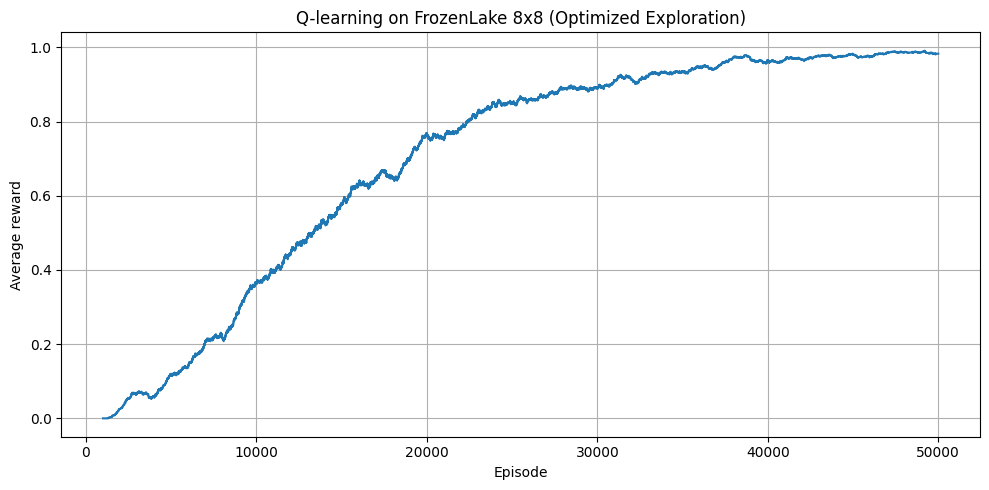

Learned Q-table (non-zero entries indicate path found):

States with learned values: 49 / 64


**Learning rate = 0.9**

Episode: 5000, Success rate (last 5k): 0.047, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.254, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.497, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.676, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.805, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.878, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.926, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.957, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.974, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.982, Epsilon: 0.010

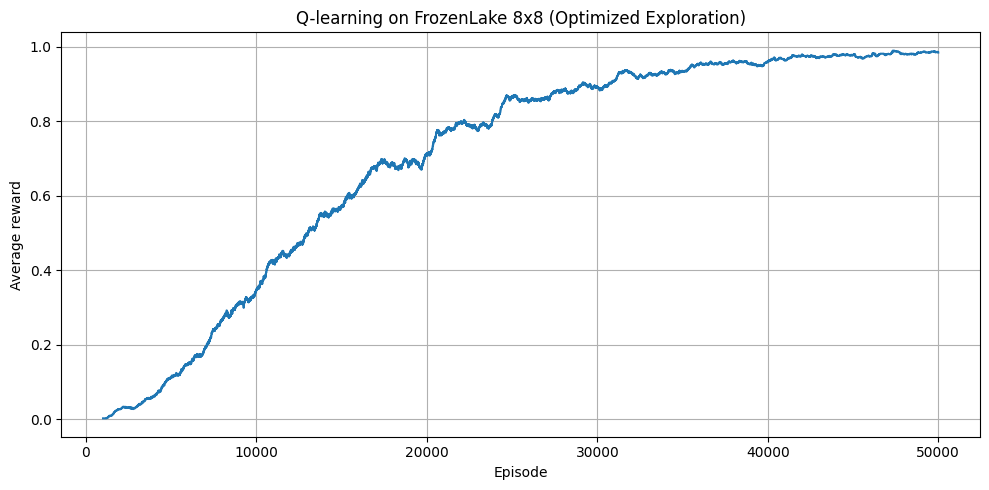

Learned Q-table (non-zero entries indicate path found):

States with learned values: 50 / 64


# **Discount-factor experiment**

0.75 did best in early learning, with 0.50 and 0.90 catching up shortly after. 0.50 finished with the highest success rate by a narrow margin. Overall, 0.50 is the best because it ended with the highest success rate, but they are all  performed similarly.

**Discount-factor = 0.50**

Episode: 5000, Success rate (last 5k): 0.066, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.279, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.502, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.682, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.804, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.874, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.925, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.958, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.977, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.983, Epsilon: 0.010

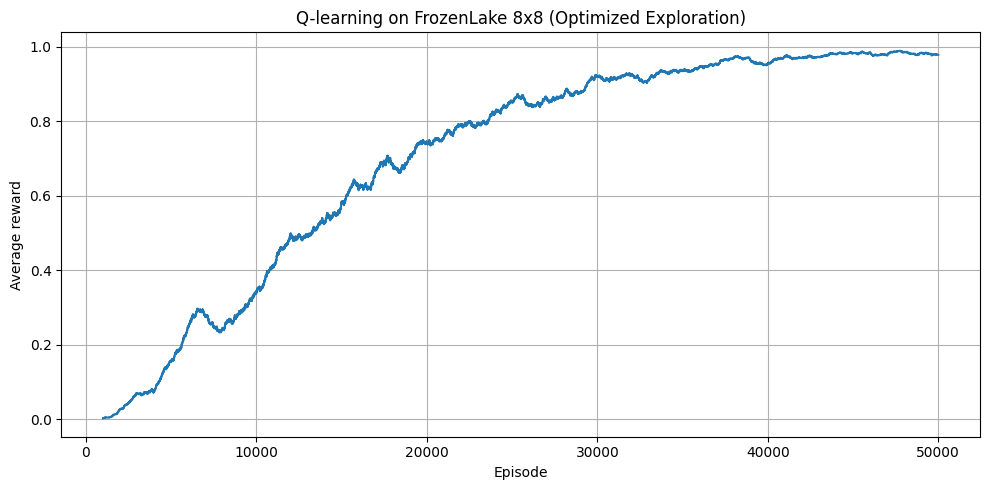

Learned Q-table (non-zero entries indicate path found):

States with learned values: 50 / 64

**Discount Factor = 0.75**

Episode: 5000, Success rate (last 5k): 0.101, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.375, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.498, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.681, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.806, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.871, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.925, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.949, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.968, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.982, Epsilon: 0.010

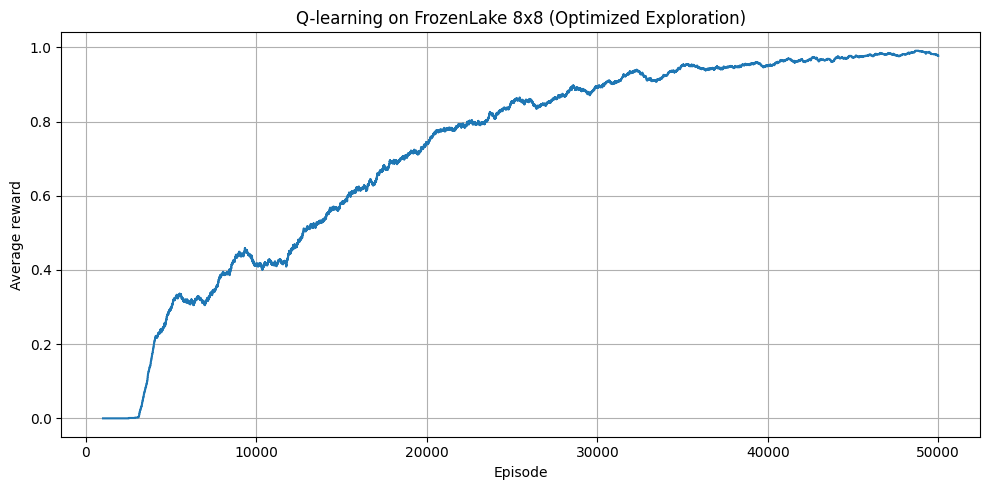

Learned Q-table (non-zero entries indicate path found):

States with learned values: 47 / 64

**Discount Factor = 0.90

Episode: 5000, Success rate (last 5k): 0.094, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.321, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.498, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.677, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.801, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.883, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.927, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.953, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.974, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.980, Epsilon: 0.010

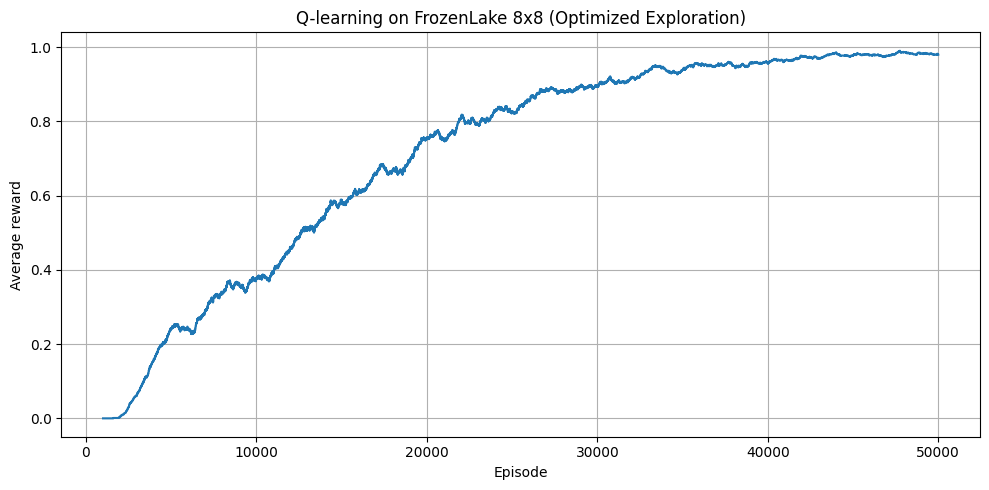

Learned Q-table (non-zero entries indicate path found):

States with learned values: 48 / 64

# **Episodes Experiment**

They all perform similarly in early learning, with 90000 doing the best by a small measure. They all had a substantial increase in learning, but 10000 was unable to reach a success rate over 0.382 due to lack of episodes to work with. 50000 and 90000 reach a high success rate, but seem to planteau at this high success rate. Due to this dual plateau at around 98.6%, 90000 is not needed, and 50000 is sufficient and best for this model.

**Episodes = 10000**

Episode: 5000, Success rate (last 5k): 0.104, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.382, Epsilon: 0.368

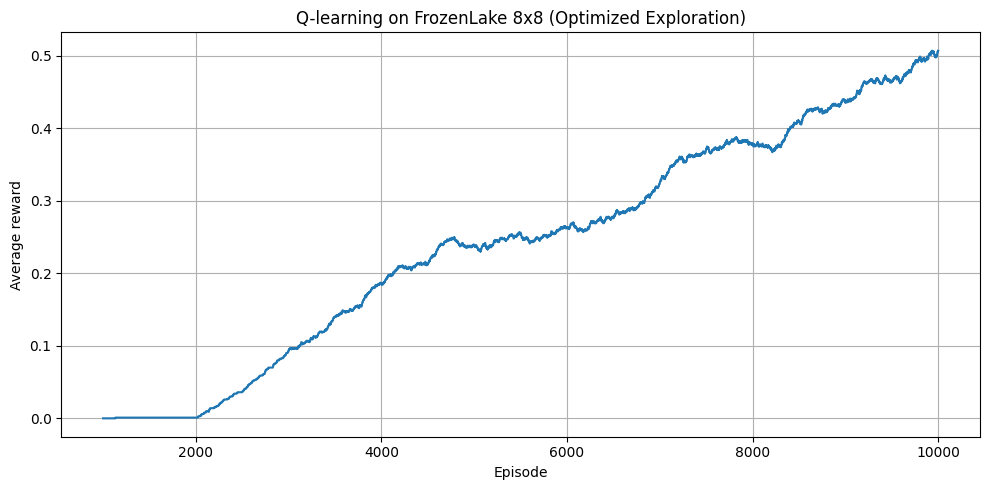

Learned Q-table (non-zero entries indicate path found):

States with learned values: 48 / 64

**Episodes = 50000**

Episode: 5000, Success rate (last 5k): 0.094, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.370, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.562, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.682, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.801, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.884, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.930, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.957, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.973, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.986, Epsilon: 0.010

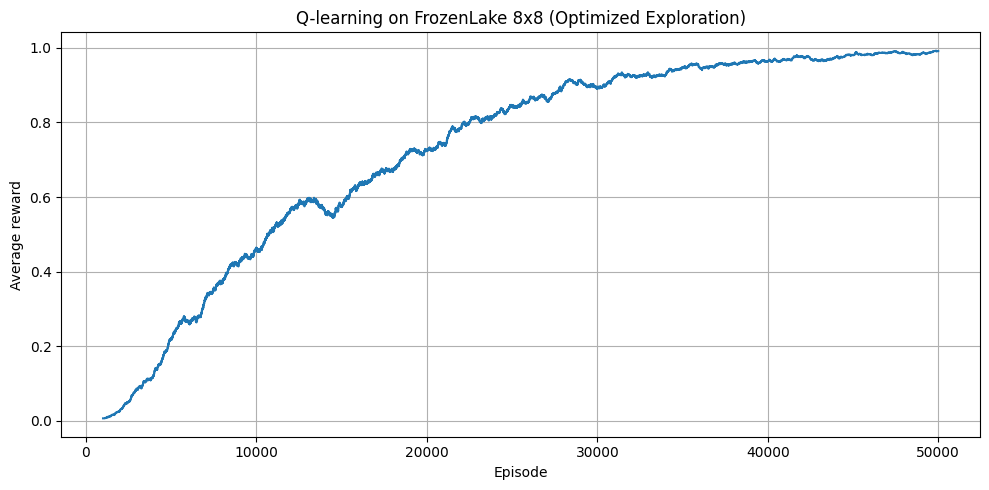

Learned Q-table (non-zero entries indicate path found):

States with learned values: 48 / 64

**Episodes = 90000**

Episode: 5000, Success rate (last 5k): 0.121, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.385, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.628, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.776, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.866, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.916, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.951, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.972, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.983, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.988, Epsilon: 0.010

Episode: 55000, Success rate (last 5k): 0.989, Epsilon: 0.010

Episode: 60000, Success rate (last 5k): 0.989, Epsilon: 0.010

Episode: 65000, Success rate (last 5k): 0.988, Epsilon: 0.010

Episode: 70000, Success rate (last 5k): 0.990, Epsilon: 0.010

Episode: 75000, Success rate (last 5k): 0.987, Epsilon: 0.010

Episode: 80000, Success rate (last 5k): 0.986, Epsilon: 0.010

Episode: 85000, Success rate (last 5k): 0.987, Epsilon: 0.010

Episode: 90000, Success rate (last 5k): 0.986, Epsilon: 0.010

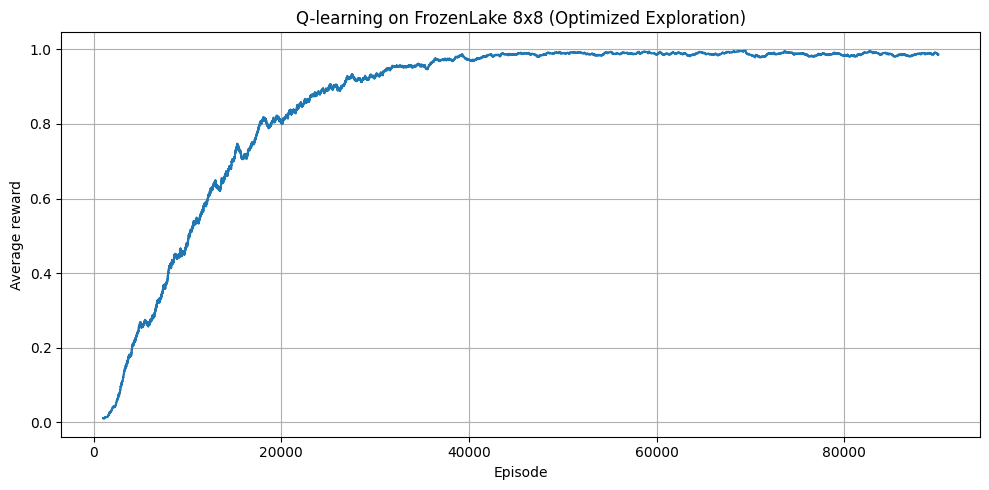

Learned Q-table (non-zero entries indicate path found):

States with learned values: 49 / 64

# **Best Agent**

**Parameters**

The following are the parameters that I determined to be the best, based on the experiments performed on learning rate, discount factor, and number of episodes.


- Learning rate: 0.5
- Discount factor: 0.50
- Initial exploration rate: 1.0
- Minimum exploration rate: 0.01
- Exploration decay rate: -.9999
- Number of training episodes: 50000
- Maximum steps per episode: 100
- Slippery transitions: disabled
- Schedule: exponantial decay

**Evaluation**

This model proved to be successful, reaching 0.98 success rate by the end, and learning well early.

**Results**

Episode: 5000, Success rate (last 5k): 0.050, Epsilon: 0.607

Episode: 10000, Success rate (last 5k): 0.241, Epsilon: 0.368

Episode: 15000, Success rate (last 5k): 0.482, Epsilon: 0.223

Episode: 20000, Success rate (last 5k): 0.669, Epsilon: 0.135

Episode: 25000, Success rate (last 5k): 0.794, Epsilon: 0.082

Episode: 30000, Success rate (last 5k): 0.875, Epsilon: 0.050

Episode: 35000, Success rate (last 5k): 0.927, Epsilon: 0.030

Episode: 40000, Success rate (last 5k): 0.953, Epsilon: 0.018

Episode: 45000, Success rate (last 5k): 0.974, Epsilon: 0.011

Episode: 50000, Success rate (last 5k): 0.980, Epsilon: 0.010

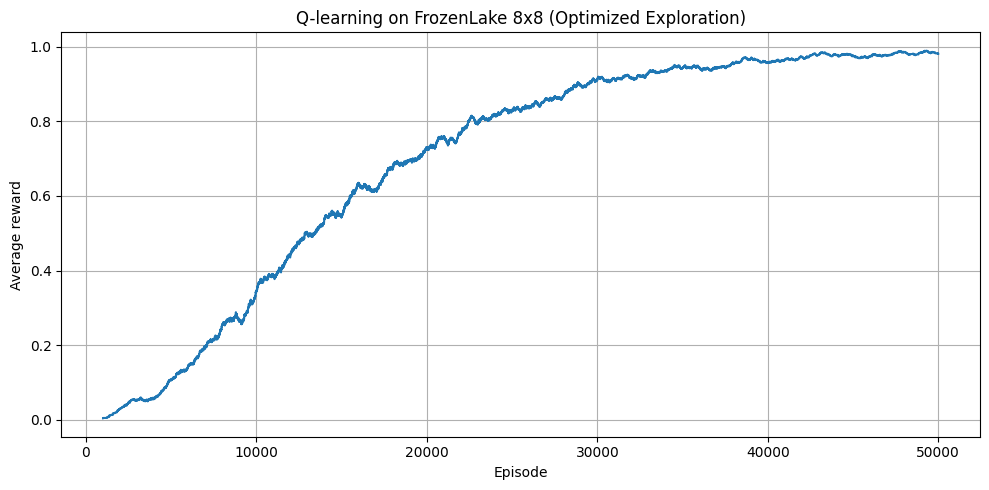

Learned Q-table (non-zero entries indicate path found):

States with learned values: 51 / 64


Episode: 5000, Success rate (last 5k): 0.005, Epsilon: 0.607
Episode: 10000, Success rate (last 5k): 0.009, Epsilon: 0.368
Episode: 15000, Success rate (last 5k): 0.014, Epsilon: 0.223
Episode: 20000, Success rate (last 5k): 0.022, Epsilon: 0.135
Episode: 25000, Success rate (last 5k): 0.027, Epsilon: 0.082
Episode: 30000, Success rate (last 5k): 0.044, Epsilon: 0.050
Episode: 35000, Success rate (last 5k): 0.043, Epsilon: 0.030
Episode: 40000, Success rate (last 5k): 0.056, Epsilon: 0.018
Episode: 45000, Success rate (last 5k): 0.040, Epsilon: 0.011
Episode: 50000, Success rate (last 5k): 0.083, Epsilon: 0.010


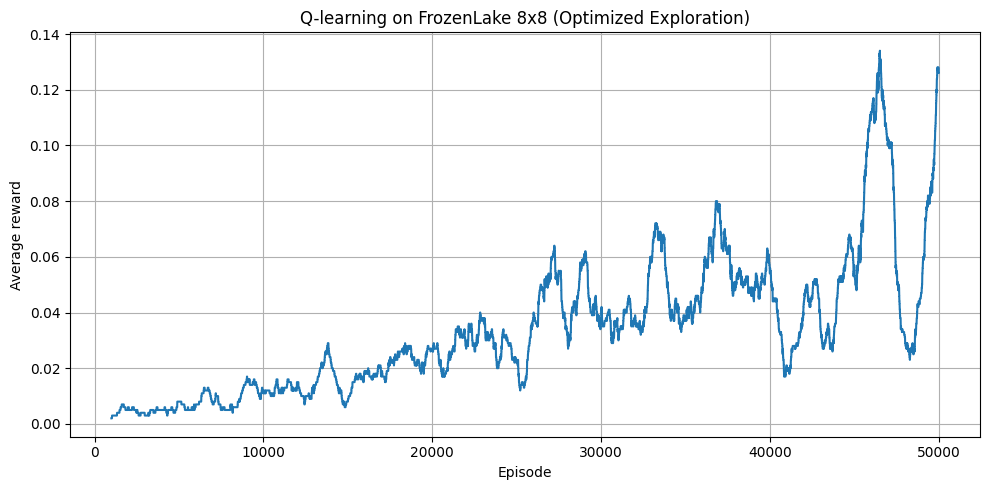


Learned Q-table (non-zero entries indicate path found):
States with learned values: 53 / 64


In [20]:
#stochastic
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# environment
env = gym.make(
    "FrozenLake-v1",
    map_name="8x8",
    is_slippery=True
)

# hyperparameters optimized for sparse reward exploration
alpha = 0.5            # learning rate
gamma = 0.50           # discount factor
epsilon = 1.0          # initial exploration probability
epsilon_min = 0.01     # minimum exploration probability
epsilon_decay = 0.9999 # slower decay to ensure enough early-stage exploration

episodes = 50000
max_steps = 100

# reproducibility
np.random.seed(42)

# initialize the Q-table
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

# store episode rewards and successes
episode_rewards = []
episode_successes = []

# training loop
for episode in range(episodes):

    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):

        # epsilon-greedy action selection
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            # Add a small random choice among best actions to break ties randomly when Q is all zeros
            best_actions = np.flatnonzero(Q[state] == np.max(Q[state]))
            action = np.random.choice(best_actions)

        # take action
        next_state, reward, terminated, truncated, info = env.step(action)

        # Q-learning update
        target = reward
        if not terminated:
            target += gamma * np.max(Q[next_state])

        Q[state, action] += alpha * (target - Q[state, action])

        # move to next state
        state = next_state
        total_reward += reward

        # stop if episode ends
        if terminated or truncated:
            break

    # decay exploration after each episode
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    episode_rewards.append(total_reward)
    episode_successes.append(int(total_reward > 0))

    # display progress
    if (episode + 1) % 5000 == 0:
        recent_success = np.mean(episode_successes[-5000:])
        print(
            f"Episode: {episode + 1}, "
            f"Success rate (last 5k): {recent_success:.3f}, "
            f"Epsilon: {epsilon:.3f}"
        )

env.close()

# plot training rewards
window = 1000
average_rewards = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))
plt.plot(
    np.arange(window, len(episode_rewards) + 1),
    average_rewards
)
plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("Q-learning on FrozenLake 8x8 (Optimized Exploration)")
plt.grid(True)
plt.tight_layout()
plt.show()

# display learned Q-table
print("\nLearned Q-table (non-zero entries indicate path found):")
non_zero_rows = np.any(Q > 0, axis=1)
print(f"States with learned values: {np.sum(non_zero_rows)} / {n_states}")

# save Q-table for later evaluation
np.save("frozenlake_qtable.npy", Q)

# **Stochastic environment**

Turning slippery tiles on makes it so that there is a 1/3 chance that the agent does not move to its intended tile, making it more likely to fail by going into a hole. I kept all parameters the same as the "best" version of the original model. The stochastity caused the rate of success to increase more slowly, reaching 0.070, in comparison to the 0.980 of this model minus its stochastity. The Q-learning graph is also a lot more jagged due to the random actions leading to failure.